# A first run of the crusher engine on the reference secondary cone

**Question:** What product size, throughput and power does a secondary cone give at the reference operating point S01, and how far is the same engine from one measured plant survey?

- **Level:** 1, Fundamentals
- **Prerequisites:** none, this is the entry notebook
- **Reading time:** about 25 minutes

## Objectives

By the end of this notebook you can:

- describe an operating point of a crusher with the eight numbers the studio asks for, and say what each one controls;
- run the product's engine once and read the product size P80, the throughput in tonnes per hour and the power in kilowatts;
- read the sieve grid that every size distribution of the engine lives on;
- load the table of ten measured surveys of an industrial cone, run the engine at one of them, and see how far a model number is from a plant number.

## Setup

Every notebook of the set is pinned in `notebooks/requirements.txt` and runs in the `.venv-notebooks` environment that `scripts/setup.sh --notebooks` builds (`scripts/setup.ps1 -Notebooks` on Windows). This notebook needs numpy for the arrays and matplotlib for the figures:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

ChancaDEM publishes no package of its own: its engine is the folder `data-pipeline/pipeline/model/crusher/`, so the cell below imports it by its path, as every notebook of this set does. The cell also prints the versions of the two libraries.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher import evaluate, Operating, operating_from_survey, grid_edges, grid_mid
from pipeline.hp500.surveys import read_surveys
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

Two sources, both committed to the repository.

- The reference case S01, a synthetic secondary-cone operating point authored for the studio. Owner: this repository, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Licence class: MIT; the committed artifacts are written by the pipeline from the parameters of each case. File read: `data/derived/manifests/S01.json`, whose `params` block holds the operating point.
- The ten surveys of a Metso HP500 secondary cone at the Minas Rio iron ore operation. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. File read: `data/examples/hp500-surveys.csv`, read through the survey reader of the pipeline, which parses every cell and rejects a row with a reason instead of coercing it.

The next cell reads the manifest of S01 and prints its operating point. A missing file stops the notebook with its path in the error.

In [2]:
# Read the manifest of the reference case and keep its parameter block
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
params = manifest["params"]
for key, value in params.items():
    print(f"{key:12s} {value}")

machine      cone-sec
css_mm       32.0
throw_mm     30.0
speed_rpm    360.0
feed_x63_mm  90.0
feed_m       1.2
ore_axb      55.0
ore_wi       14.0
calibrated   False


## Method

**Step 1, the operating point.** The engine takes one `Operating` record. Three numbers set the machine: the closed-side setting CSS (the narrowest gap between the mantle and the bowl, in mm), the eccentric throw (so that the open-side setting is OSS = CSS + throw) and the speed in rev/min. Two numbers describe the feed as a Rosin-Rammler distribution (Rosin and Rammler, 1933; https://cir.nii.ac.jp/crid/1572543024341127296): the characteristic size x63 where 63.2 percent of the mass passes and the uniformity exponent m. Two numbers describe the ore: the JKMRC drop-weight competence A*b (lower is harder) and the Bond work index Wi in kWh/t. The last field, `calibrated`, selects the HP500 fit and is False for synthetic cases.

The cell builds the record from the manifest.

In [3]:
# Build the operating point; the record is frozen, so a run can never change it
op = Operating(**params)
print(op)
print("open-side setting OSS [mm]:", op.css_mm + op.throw_mm)

Operating(machine='cone-sec', css_mm=32.0, throw_mm=30.0, speed_rpm=360.0, feed_x63_mm=90.0, feed_m=1.2, ore_axb=55.0, ore_wi=14.0, calibrated=False)
open-side setting OSS [mm]: 62.0


**Step 2, one evaluation.** `evaluate` runs the whole chain of the engine on the record: it discretises the feed on the sieve grid, builds the classification and breakage functions, solves the Whiten population balance for the product (Whiten, 1972; https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf), and then reads the capacity and the power. The result holds the full distributions and a set of scalar readouts, which the cell prints. F80 and P80 are the sizes that 80 percent of the feed and of the product pass, and the reduction ratio is F80 over P80 (Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193).

In [4]:
# Run the engine once and print the scalar readouts
result = evaluate(op)
print(f"F80 = {result.f80:.2f} mm")
print(f"P80 = {result.p80:.2f} mm")
print("reduction ratio", f"= {result.reduction_ratio:.2f}")
print("throughput", f"= {result.throughput_tph:.0f} t/h")
print("power", f"= {result.power_kw:.0f} kW")
print("regime", result.regime, "| valid", result.valid)

F80 = 126.03 mm
P80 = 27.70 mm
reduction ratio = 4.55
throughput = 643 t/h
power = 287 kW
regime choke | valid True


**Step 3, the sieve grid.** Every distribution of the engine lives on one fixed grid of 28 size classes, from a 256 mm top size down by a factor of the square root of two per class, the standard laboratory sieve series. The grid edges descend from coarse to fine; the mid-size of a class is the geometric mean of its two edges. The cell prints the ends of the grid and the mass of the feed and of the product in the classes around the product P80, to see where the crusher moves the mass.

In [5]:
# Show the grid ends and the mass per class of the feed and the product near P80
edges, mids = grid_edges(), grid_mid()
print("classes:", len(mids), "| top edge", round(edges[0], 1), "mm", "| bottom edge", round(edges[-1], 4), "mm")
near = [i for i, m in enumerate(mids) if 8 <= m <= 70]
print("mid size [mm]   feed mass   product mass")
for i in near:
    print(f"{mids[i]:10.2f} {result.feed.mass[i]:12.4f} {result.product.mass[i]:12.4f}")

classes: 28 | top edge 256.0 mm | bottom edge 0.0156 mm
mid size [mm]   feed mass   product mass
     53.82       0.1346       0.0217
     38.05       0.1070       0.1094
     26.91       0.0798       0.1653
     19.03       0.0571       0.1246
     13.45       0.0398       0.0976
      9.51       0.0272       0.0780


The table shows the crusher's work in one glance: the class around 54 mm holds 13.5 percent of the feed and only 2.2 percent of the product, and the product mass peaks in the class around 27 mm with 16.5 percent. The figure below draws the same information as cumulative passing curves on a logarithmic size axis, the way a plant metallurgist reads a sieve analysis, with F80 and P80 marked.

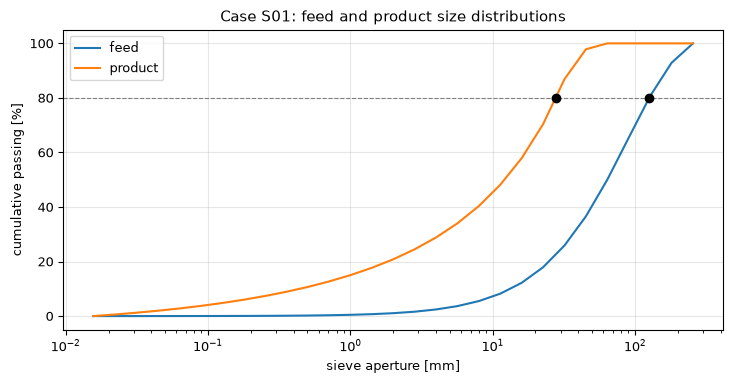

In [6]:
# Plot the cumulative passing of the feed and the product of S01 and mark F80 and P80
fig, ax = plt.subplots()
ax.plot(edges, np.array(result.feed.passing) * 100, label="feed")
ax.plot(edges, np.array(result.product.passing) * 100, label="product")
ax.axhline(80, color="grey", lw=0.8, ls="--")
ax.plot([result.f80, result.p80], [80, 80], "ko")
ax.set_xscale("log")
ax.set_xlabel("sieve aperture [mm]")
ax.set_ylabel("cumulative passing [%]")
ax.set_title("Case S01: feed and product size distributions")
ax.legend()
fig.tight_layout()
plt.show()

The two curves are one Rosin-Rammler feed and the product the Whiten solve derives from it. The horizontal dashed line is the 80 percent level where F80 and P80 are read; the gap between the two black dots is the size reduction the machine achieved at this setting. What the figure does not show is why the product has this shape. That needs the breakage and classification functions, which topic 03 opens one by one.

**Step 4, a plant survey.** The studio's second lane is real data. The survey reader parses the CSV of the ten HP500 surveys cell by cell, with a bounds check per column, and returns the accepted rows and the rejected rows with their reasons. The cell prints both counts and the first survey. Each survey gives the setting, the feed f80, the feed rate in t/h and the power in kW that the plant measured.

In [7]:
# Read the survey table; a row outside its bounds would appear in the rejected list with its reason
report = read_surveys()
print("accepted:", len(report.accepted), "| rejected:", len(report.rejected))
survey = report.accepted[0]
print(survey)

accepted: 10 | rejected: 0
Survey(survey=1, f80_mm=88.0, css_mm=54.0, feed_tph=1639.0, power_kw=209.0)


**Step 5, the engine at a survey.** `operating_from_survey` turns a survey into an operating point on the calibrated lane: the measured setting and f80 are used as given, the throw and the speed are the HP500 constants, and the feed shape is rebuilt from the f80 with a Rosin-Rammler uniformity of 0.9. The calibrated lane replaces the synthetic classification and breakage with the Andersen-Whiten fit that Rocha et al. (2024; https://doi.org/10.3390/min14090919) published in their Table 5. The cell runs the engine at survey 1 and sets the model next to the measurement.

In [8]:
# Run the calibrated engine at survey 1 and compare it with what the plant measured
real = evaluate(operating_from_survey(survey.css_mm, survey.f80_mm))
gap_tph = (real.throughput_tph - survey.feed_tph) / survey.feed_tph * 100
gap_kw = (real.power_kw - survey.power_kw) / survey.power_kw * 100
print(f"CSS = {survey.css_mm:.0f} mm, f80 = {survey.f80_mm:.0f} mm, P80 = {real.p80:.2f} mm")
print("throughput", f"measured {survey.feed_tph:.0f} t/h, model {real.throughput_tph:.0f} t/h, gap {gap_tph:+.1f} %")
print("power", f"measured {survey.power_kw:.0f} kW, model {real.power_kw:.0f} kW, gap {gap_kw:+.1f} %")

CSS = 54 mm, f80 = 88 mm, P80 = 32.56 mm
throughput measured 1639 t/h, model 1209 t/h, gap -26.2 %
power measured 209 kW, model 408 kW, gap +95.4 %


Before reading the numbers, the cell below puts them on one chart: the model's throughput and power against the plant's, for the one survey just computed. A reader sees at once that the two quantities do not disagree in the same way.

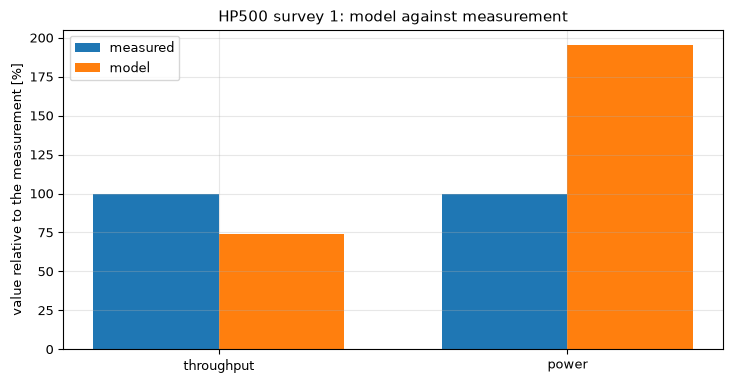

In [9]:
# Bar chart of measured against modelled throughput and power for survey 1, each relative to the measurement
labels = ["throughput", "power"]
measured = np.array([survey.feed_tph, survey.power_kw])
modelled = np.array([real.throughput_tph, real.power_kw])
x = np.arange(2)
fig, ax = plt.subplots()
ax.bar(x - 0.18, np.ones(2) * 100, 0.36, label="measured")
ax.bar(x + 0.18, modelled / measured * 100, 0.36, label="model")
ax.set_xticks(x, labels)
ax.set_ylabel("value relative to the measurement [%]")
ax.set_title("HP500 survey 1: model against measurement")
ax.legend()
fig.tight_layout()
plt.show()

The throughput bar of the model is shorter than the measured one and the power bar is taller, so the model undershoots the plant's tonnage and overshoots its power. One survey proves nothing about a model, and a single bar never says whether a gap is typical; topic 05 repeats this comparison on all ten surveys and topic 06 asks how much of the gap a held-out validation can honestly claim. For now the figure only fixes the order of magnitude: the engine is in the right range on tonnage and not in the right range on power.

## Results

**Answer:** at the reference point S01 (CSS 32 mm, throw 30 mm, 360 rpm, a feed of F80 126.03 mm) the engine returns a product P80 of 27.70 mm, a reduction ratio of 4.55, a throughput of 643 t/h and a power of 287 kW, in the choke regime and valid. Run at HP500 survey 1 (CSS 54 mm, f80 88 mm) it returns 1209 t/h against the 1639 t/h the plant fed, 26.2 percent short, and 408 kW against 209 kW measured, a model value 95 percent above the plant.

What the first figure shows: the product curve sits to the left of the feed curve everywhere, the 80 percent crossing moved from 126 mm to 28 mm, and nothing was created or lost on the way, because both curves end at 100 percent. What it does not show: the three numbers of the answer are outputs of a model, not measurements, and for S01 there is no plant to compare with, since S01 is a synthetic reference point. What the second figure shows: against a real survey the throughput gap and the power gap have opposite signs. A validator would conclude that the single survey cannot separate a bias from noise, and that the power gap deserves its own analysis, which topic 04 and topic 06 give.

## Summary

An operating point is eight numbers; `evaluate` turns it into a product size distribution on a 28-class square-root-of-two grid plus throughput and power in one call. The same call serves the synthetic cases and the calibrated HP500 lane. A plant survey is a different kind of evidence from a model run: the reader needs the survey's own numbers beside the model's. The next notebook of this topic replays all 27 baked cases against the live engine, and topic 02 takes the feed apart.

## References

- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Rosin, P., Rammler, E. (1933), The laws governing the fineness of powdered coal, Journal of the Institute of Fuel 7, 29-36. https://cir.nii.ac.jp/crid/1572543024341127296